# Обзор датасетов: «Балтийский баланс — 2030»

**Рабочий ноутбук Data Engineer.** Запускайте ячейки сверху вниз: `Run → Run All Cells`.
За один проход вы получите состав данных, источники, периоды, пропуски, графики и таблицу пригодности для команды.

Здесь исследуются **опубликованные показатели и ограничения их покрытия**. Выбор цели прогноза остаётся за командой.
Годовые значения сохраняются годовыми, отсутствующие значения не заменяются нулями.
Внешняя торговля региона, портовая перевалка, транзитные записи и мощность терминала рассматриваются отдельно.

**Перед первым запуском:** в терминале из корня проекта выполните `pip install -e ".[data,notebooks]"`,
выберите Python из `.venv`, затем `python -m pipeline.build --available-only` и `python -m pipeline.verify`.
Нужны оригиналы и подготовленные CSV из рабочей папки или архива передачи; одного клона Git недостаточно.
Интернет требуется для установки пакетов, сам обзор читает только локальные файлы.

Маршрут: **проверка комплекта → инвентаризация → источники → качество → паромная линия → контекст → экспорт → транзит → выводы**.


## 1. Окружение и проверка комплекта

Ячейки не скачивают файлы и не изменяют исходные таблицы. Корень проекта находится автоматически,
если Jupyter открыт из корня или папки `notebooks/`. При изменении исходников сначала пересоберите данные в терминале.


In [1]:
import csv
import json
import sys
from decimal import Decimal
from pathlib import Path

try:
    import pandas as pd
    import matplotlib.pyplot as plt
    from IPython.display import Markdown, display
except ImportError as error:
    raise ImportError('В выбранном Python нужны зависимости: pip install -e ".[notebooks]"') from error

get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 30)
pd.set_option("display.max_colwidth", 85)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.2,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.family": "DejaVu Sans", "figure.dpi": 110})

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "data/source_registry.json").is_file() and (p / "pipeline").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте Jupyter из корня проекта или папки notebooks; нужен data/source_registry.json.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Проект:", ROOT)
print("Python:", sys.executable)
print("pandas:", pd.__version__)


Проект: /home/pyanz/Code/not_found
Python: /home/pyanz/Code/not_found/.venv-1/bin/python
pandas: 3.1.1


In [2]:
from pipeline.verify import verify

manifest_path = ROOT / "data/processed/build_manifest.json"
if not manifest_path.is_file():
    raise FileNotFoundError("Нет подготовленных таблиц. Получите оригиналы и выполните python -m pipeline.build --available-only.")
verification_errors = verify(ROOT)
if verification_errors:
    raise ValueError("Комплект требует проверки. После изменения кода выполните python -m pipeline.build --available-only.\n" +
                     "\n".join(verification_errors[:10]))
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
registry = json.loads((ROOT / "data/source_registry.json").read_text(encoding="utf-8"))
print("Версия данных:", manifest["data_version"])
print("Целевой ряд:", manifest["target_selection"], "— ожидает решения команды")
print("Хеши, происхождение, единицы и согласованность сводок: проверены.")

print("Режим сборки:", manifest.get("build_scope", "full"))
print("Отсутствующих оригиналов:", len(manifest.get("unavailable_source_ids", [])))
print("Анализируются только CSV из манифеста; остатки прежних сборок не используются.")


Версия данных: bb-data-4c7c6758e675
Целевой ряд: pending — ожидает решения команды
Хеши, происхождение, единицы и согласованность сводок: проверены.
Режим сборки: available_only
Отсутствующих оригиналов: 13
Анализируются только CSV из манифеста; остатки прежних сборок не используются.


## 2. Какие таблицы есть

Число строк не равно числу временных точек или перевозок. Например, два направления по девять лет —
это две отдельные истории по девять точек; у одной транзитной декларации бывает несколько товаров.
`exports_kaliningrad.csv` — подвыборка `exports_clean.csv`, а месячная сводка транзита построена из товарных строк.
Эти производные файлы не добавляют независимых наблюдений.

**Где лежат таблицы и откуда они получены.** Все пути ниже указаны **от корня проекта**.
Сохранённые оригиналы перечислены для комплекта `bb-data-015224e90bac`; связь конкретной строки с оригиналом — через `source_id` в `data/source_registry.json`.

| Файл в проекте | Происхождение |
|---|---|
| `data/processed/candidate_observations.csv` | [Росморпорт: погрузочно-разгрузочная деятельность](https://www.rosmorport.ru/filials/spb_serv_freight/); строки паромной линии, раздел 5 |
| `data/processed/context_observations.csv` | [Деятельность терминала](https://www.rosmorport.ru/filials/spb_serv_freight/) и [перевозки филиала](https://www.rosmorport.ru/filials/spb_serv_ferry/); раздел 6 |
| `data/processed/coverage.csv` | Рассчитано из `candidate_observations.csv` и `context_observations.csv`; отдельного внешнего источника нет |
| `data/processed/scenario_parameters.csv` | Заявленные мощности объектов на [странице Росморпорта](https://www.rosmorport.ru/filials/spb_serv_freight/); раздел 6 |
| `data/processed/factors.csv` | Пока только схема: исходные значения факторов ещё не добавлены |
| `data/processed/exports_clean.csv` | Три присланных XLSX: ЭК, НЭ, ННЭ; пути к оригиналам в разделе 7 |
| `data/processed/exports_kaliningrad.csv` | Фильтр `exports_clean.csv` по Калининградской области |
| `data/processed/export_growth_checks.csv` | Сверка значений и опубликованных индексов из тех же трёх XLSX; раздел 7 |
| `data/processed/transit_items_clean.csv` | Присланный `2204_tranzit_EN.xls`; путь к оригиналу в разделе 8 |
| `data/processed/transit_monthly_summary.csv` | Группировка `transit_items_clean.csv` по месяцу оформления, странам, транспорту и товарной группе |
| `data/processed/table_row_issues.csv` | Журнал обработки экспортных и транзитного файлов; отдельного внешнего источника нет |
| `data/interim/reconciliation.csv` | Диагностическая разность показателей линии и терминала из сохранённой страницы Росморпорта |
| `data/source_catalog.csv` | [Предоставленная Google-таблица](https://docs.google.com/spreadsheets/d/1lWth7AgxGWDGiAHEXNgSjNQTaCmZDxHrBlmADg6GWLQ/edit); оригинал XLSX указан в разделе 3 |



In [3]:
# Имена кодов, стран и товарных групп читаются строками: ведущие нули сохраняются.
# keep_default_na=False не превращает код страны NA или текст ND в пропуск.
relative_csvs = sorted(p for p in manifest["outputs"] if p.endswith(".csv"))
tables = {Path(p).name: pd.read_csv(ROOT / p, dtype="string", encoding="utf-8-sig", keep_default_na=False)
          for p in relative_csvs}

dataset_roles = {
    "candidate_observations.csv": "Кандидат цели: узкая паромная линия, два направления",
    "context_observations.csv": "Контекст: терминал и перевозки филиала, иной охват",
    "coverage.csv": "Аудит покрытия отдельных рядов",
    "exports_clean.csv": "Внешняя торговля всех представленных территорий",
    "exports_kaliningrad.csv": "Подвыборка области из exports_clean",
    "export_growth_checks.csv": "Диагностика индексов роста, не новые наблюдения",
    "transit_items_clean.csv": "Товарные строки выборки транзитных деклараций",
    "transit_monthly_summary.csv": "Производная сводка товарных строк, не уникальные отправки",
    "scenario_parameters.csv": "Заявленные мощности объектов, не факт перевозки",
    "factors.csv": "Заготовка факторов; доступность и лаги пока не подтверждены",
    "table_row_issues.csv": "Журнал повторов и конфликтов ключей",
    "reconciliation.csv": "Диагностика различия охвата линии и терминала",
    "source_catalog.csv": "Каталог ссылок; статус оригинала смотрите в журнале сборки",
    "regional_indicators.csv": "Региональные показатели всех разделов; версии сохранены",
    "regional_freight.csv": "Грузовой срез региона; нужный OD не выделен",
    "supplemental_freight.csv": "Раздельные частичные ряды публикаций; охват и точность в полях",
    "port_cabotage_cumulative.csv": "Портовый каботаж с января; сравнительные годы и версии",
    "port_cabotage_monthly.csv": "Оценки разностей накоплений, не наблюдения OD",
    "border_crossings.csv": "Пересечения грузовых автомобилей, не тонны",
    "freight_coverage.csv": "Оценка покрытия четырёх грузовых каналов",
    "supplemental_issues.csv": "Служебные коды, версии, расхождения и пропуски соседних месяцев",
}

def period_range(frame):
    for column in ("period", "registered_date"):
        if column in frame:
            values = frame.loc[frame[column].ne(""), column]
            return f"{values.min()} — {values.max()}" if not values.empty else "нет значений"
    return "не временной ряд"

inventory = pd.DataFrame([
    {"file": name, "rows": len(frame), "columns": len(frame.columns),
     "period_range": period_range(frame), "role": dataset_roles.get(name, "Дополнительная таблица")}
    for name, frame in tables.items()
])
display(inventory)


,file,rows,columns,period_range,role
0,reconciliation.csv,0,5,нет значений,Диагностика различия охвата линии и терминала
1,border_crossings.csv,228,11,2022-01 — 2026-09,"Пересечения грузовых автомобилей, не тонны"
2,candidate_observations.csv,0,18,нет значений,"Кандидат цели: узкая паромная линия, два направления"
3,context_observations.csv,0,16,нет значений,"Контекст: терминал и перевозки филиала, иной охват"
4,coverage.csv,0,11,не временной ряд,Аудит покрытия отдельных рядов
5,export_growth_checks.csv,3384,14,не временной ряд,"Диагностика индексов роста, не новые наблюдения"
6,exports_clean.csv,2256,16,2021-01 — 2022-01,Внешняя торговля всех представленных территорий
7,exports_kaliningrad.csv,24,16,2021-01 — 2022-01,Подвыборка области из exports_clean
8,factors.csv,0,9,нет значений,Заготовка факторов; доступность и лаги пока не подтверждены
9,freight_coverage.csv,4,6,не временной ряд,Оценка покрытия четырёх грузовых каналов


### Посмотреть любую таблицу

Поменяйте `PREVIEW_DATASET` и число строк. Справочник всех столбцов ниже помогает понять схему;
полные названия, единицы и правила агрегации описаны в `docs/contracts.md`.

После выбора файла ячейка выводит его **полный путь на вашей машине**, а при наличии `source_id` —
адрес получения и полный путь к каждому использованному оригиналу. Для производных таблиц без `source_id`
происхождение указано в таблице раздела 2.



In [4]:
PREVIEW_DATASET = "exports_kaliningrad.csv" if "exports_kaliningrad.csv" in tables else next(iter(tables))
PREVIEW_ROWS = 6
preview = tables[PREVIEW_DATASET]
display(pd.DataFrame({"column": preview.columns, "storage_type": preview.dtypes.astype(str).values}))
display(preview.head(PREVIEW_ROWS))

# Путь выбранного CSV и оригиналы именно тех source_id, которые есть в этой таблице.
preview_relative = next(p for p in relative_csvs if Path(p).name == PREVIEW_DATASET)
print("Обработанная таблица:", ROOT / preview_relative)
if "source_id" in preview.columns:
    preview_source_ids = set(preview.loc[preview["source_id"].ne(""), "source_id"])
    for artifact in registry["artifacts"]:
        if artifact["source_id"] in preview_source_ids:
            origin = artifact["url"]
            label = "Передан пользователем: " + origin.removeprefix("provided:") if origin.startswith("provided:") else origin
            print("\nИсточник:", label)
            print("Оригинал:", ROOT / artifact["local_path"])
            print("source_id:", artifact["source_id"])
else:
    print("Происхождение этой производной таблицы указано в разделе 2.")


,column,storage_type
0,export_scope,string
1,export_scope_label,string
2,reporting_geography,string
3,geography_level,string
4,enterprise_group,string
5,period,string
6,period_granularity,string
7,enterprise_count,string
8,weight_tonnes,string
9,trade_value_thousand_usd,string


,export_scope,export_scope_label,reporting_geography,geography_level,enterprise_group,period,...,trade_value_usd,status,source_id,source_locator,quality_note,data_version
0,all_exports,(весь экспорт),КАЛИНИНГРАДСКАЯ ОБЛАСТЬ,region,Всего,2021-01,...,169334000,observed,exports_all_jan2022__13466a6332f7,Лист1!B128:D128,"Внешняя торговля региона, не перевозки коридора; виды экспорта, уровни географии ...",bb-data-4c7c6758e675
1,all_exports,(весь экспорт),КАЛИНИНГРАДСКАЯ ОБЛАСТЬ,region,Всего,2022-01,...,217751000,observed,exports_all_jan2022__13466a6332f7,Лист1!E128:G128,"Внешняя торговля региона, не перевозки коридора; виды экспорта, уровни географии ...",bb-data-4c7c6758e675
2,all_exports,(весь экспорт),КАЛИНИНГРАДСКАЯ ОБЛАСТЬ,region,Микро предприятия,2021-01,...,10654000,observed,exports_all_jan2022__13466a6332f7,Лист1!B129:D129,"Внешняя торговля региона, не перевозки коридора; виды экспорта, уровни географии ...",bb-data-4c7c6758e675
3,all_exports,(весь экспорт),КАЛИНИНГРАДСКАЯ ОБЛАСТЬ,region,Микро предприятия,2022-01,...,16900000,observed,exports_all_jan2022__13466a6332f7,Лист1!E129:G129,"Внешняя торговля региона, не перевозки коридора; виды экспорта, уровни географии ...",bb-data-4c7c6758e675
4,all_exports,(весь экспорт),КАЛИНИНГРАДСКАЯ ОБЛАСТЬ,region,Малые предприятия,2021-01,...,16598000,observed,exports_all_jan2022__13466a6332f7,Лист1!B130:D130,"Внешняя торговля региона, не перевозки коридора; виды экспорта, уровни географии ...",bb-data-4c7c6758e675
5,all_exports,(весь экспорт),КАЛИНИНГРАДСКАЯ ОБЛАСТЬ,region,Малые предприятия,2022-01,...,9089000,observed,exports_all_jan2022__13466a6332f7,Лист1!E130:G130,"Внешняя торговля региона, не перевозки коридора; виды экспорта, уровни географии ...",bb-data-4c7c6758e675


Обработанная таблица: /home/pyanz/Code/not_found/data/processed/exports_kaliningrad.csv

Источник: Передан пользователем: ЭК_январь_2022.xlsx
Оригинал: /home/pyanz/Code/not_found/data/raw/exports_all_jan2022/13466a6332f767c334cd96e7ffaf3670a4a57f06c8b69ff03f4d3bf46a803c0e.xlsx
source_id: exports_all_jan2022__13466a6332f7

Источник: Передан пользователем: НЭ_январь_2022.xlsx
Оригинал: /home/pyanz/Code/not_found/data/raw/exports_non_raw_jan2022/19d8c318219e179fcb0e2fd35c1e7ab03ad17343d75dbc8d5718e0f488669ac2.xlsx
source_id: exports_non_raw_jan2022__19d8c318219e

Источник: Передан пользователем: ННЭ_январь_2022.xlsx
Оригинал: /home/pyanz/Code/not_found/data/raw/exports_non_raw_non_energy_jan2022/f831fda79ff99d600ac86e394f86513d2ff5658b7c1771cd01b9114bb3d9549c.xlsx
source_id: exports_non_raw_non_energy_jan2022__f831fda79ff9


## 3. Откуда данные и что ещё не изучено

Реестр содержит сохранённые оригиналы, включая страницы, PDF, XLS/XLSX и инструмент чтения XLS.
Наличие PDF или страницы в реестре не означает, что из них уже получен датасет.
Поля `purpose` описывают назначение источника; `observed`, `estimated`, `synthetic` описывают статус значения — это разные признаки.

**Откуда взят каталог:** [исходная Google-таблица](https://docs.google.com/spreadsheets/d/1lWth7AgxGWDGiAHEXNgSjNQTaCmZDxHrBlmADg6GWLQ/edit),
[адрес скачивания XLSX](https://docs.google.com/spreadsheets/d/1lWth7AgxGWDGiAHEXNgSjNQTaCmZDxHrBlmADg6GWLQ/export?format=xlsx). Сохранённый оригинал: `data/raw/hackathon_catalog/11a6137c973b4089f83d02d022aec7f286dabcc9c3f48f9d01197f9dd7e35198.xlsx`.
Из него получен `data/source_catalog.csv`.

**Где проверять остальные источники:** `data/source_registry.json`.
В нём `url` — адрес или указание на переданный файл, `local_path` — путь к сохранённому оригиналу,
`source_id` — идентификатор, указанный в строках обработанных таблиц.



In [5]:
sources = pd.DataFrame(registry["artifacts"])
source_columns = ["source_key", "organization", "purpose", "period", "original_unit", "url"]
display(sources[source_columns])
print("Зарегистрированных артефактов:", len(sources))
active_source_ids = {s["source_id"] for s in manifest["inputs"]}
sources["included_in_build"] = sources["source_id"].isin(active_source_ids)
print("Включено в сборку:", int(sources["included_in_build"].sum()))
display(sources.loc[~sources["included_in_build"], ["source_key", "local_path"]])
print("Уникальных source_id:", sources["source_id"].nunique())
# Для проверки конкретного оригинала: sources[["source_id", "local_path", "sha256"]]


,source_key,organization,purpose,period,original_unit,url
0,hackathon_catalog,Каталог открытых данных кейса,reference,NaN,NaN,https://docs.google.com/spreadsheets/d/1lWth7AgxGWDGiAHEXNgSjNQTaCmZDxHrBlmADg6GW...
1,rosmorport_freight,"ФГУП «Росморпорт», Северо-Западный бассейновый филиал",target_candidate,Годовые таблицы 2011–2023; в кандидат включаются только 2015–2023,тонн,https://www.rosmorport.ru/filials/spb_serv_freight/
2,rosmorport_ferry,"ФГУП «Росморпорт», Северо-Западный бассейновый филиал",reference,"2022–2025, год",тыс. тонн,https://www.rosmorport.ru/filials/spb_serv_ferry/
3,oboronlogistics_2024,ООО «Оборонлогистика»,reference,"2024, год; публикация 15.01.2025",млн тонн,https://obl.ru/pressa/news/oboronlogistika-podvela-itogi-2024-goda/
4,oboronlogistics_jan2025,ООО «Оборонлогистика»,target_candidate,2025-01,тонны / транспортные единицы — проверить по абзацам,https://obl.ru/pressa/news/pervye-itogi-goda/
...,...,...,...,...,...,...
134,seanews_2025_11,SeaNews / PORTSTAT,reference,2025-01–2025-11,тыс. тонн,https://seanews.ru/wp-content/uploads/2025/12/01-11-kabotazh-po-kompanijam-i-nome...
135,seanews_2025_12,SeaNews / PORTSTAT,reference,2025-01–2025-12,тыс. тонн,https://seanews.ru/wp-content/uploads/2026/01/01-12-kabotazh-po-kompanijam-i-nome...
136,seanews_2026_08,SeaNews / PORTSTAT,reference,2026-01–2026-08,тыс. тонн,https://seanews.ru/wp-content/uploads/2026/09/01-08-kabotazh-po-kompanijam-i-nome...
137,seanews_2026_09,SeaNews / PORTSTAT,reference,2026-01–2026-09,тыс. тонн,https://seanews.ru/wp-content/uploads/2026/10/01-09-kabotazh-po-kompanijam-i-nome...


Зарегистрированных артефактов: 139
Включено в сборку: 126


,source_key,local_path
0,hackathon_catalog,data/raw/hackathon_catalog/11a6137c973b4089f83d02d022aec7f286dabcc9c3f48f9d01197f...
1,rosmorport_freight,data/raw/rosmorport_freight/44a0339134dfbf750816304f99d26ed9167b5bc96d0effb76aa53...
2,rosmorport_ferry,data/raw/rosmorport_ferry/bd1008b9ce3f27df77509b70c9006020f52f5ebd69fefe16f691a1b...
3,oboronlogistics_2024,data/raw/oboronlogistics_2024/4ba75121097ab66b2fce6652f5cc0dc83b8077f0217d18050b2...
4,oboronlogistics_jan2025,data/raw/oboronlogistics_jan2025/1f3daf7ff9de7bb498e3757f007a31757ad0bc8384d6cbe0...
5,asop_statistics,data/raw/asop_statistics/9d97dca06f68fc43314628a93601881ef6179e95ccb8f223ba83105a...
6,tochno_regions,data/raw/tochno_regions/9c85fd507f8284838de6375251ad2d5d529e812b4429353f4932b75ab...
7,ltg_2025,data/raw/ltg_2025/5ec4c715cff516ca226226b67e6a55d7bbc39d9b55417168ced37aac16186c1...
10,oboronlogistics_apr2025,data/raw/oboronlogistics_apr2025/c25900d68a350c6c4a7fb92910f6d8054785118ccfb1257a...
11,oboronlogistics_jul2025,data/raw/oboronlogistics_jul2025/0bb30a49f080a4cf5ca2871945193fef26c04b427284f5c1...


Уникальных source_id: 139


In [6]:
# Полный каталог и неудачные получения сохраняются отдельно от проверенных таблиц.
catalog = tables.get("source_catalog.csv", pd.DataFrame())
if not catalog.empty:
    display(catalog.groupby(["purpose", "review_status"], dropna=False).size()
            .rename("links").reset_index())
    display(catalog[["title", "purpose", "review_status", "url"]])
else:
    print("Каталог ссылок отсутствует в этом комплекте.")
failures = pd.DataFrame(registry.get("failures", []))
if failures.empty:
    print("Ошибок получения в реестре нет.")
else:
    display(failures)
print("Ошибка доступа означает непроверенный источник; проверка TLS не отключается.")


,purpose,review_status,links
0,factor,discovered,6
1,factor,index_saved,1
2,reference,discovered,25
3,reference,index_saved,3
4,scenario_parameter,discovered,1
5,scenario_parameter,index_saved,1
6,target_candidate,discovered,1


,title,purpose,review_status,url
0,Точно: связность городов,reference,discovered,https://tochno.st/datasets/intercity_connectivity
1,Точно / Росстат: транспорт регионов,reference,index_saved,https://tochno.st/datasets/regions_collection
2,АСОП: грузооборот и мощности портов,scenario_parameter,index_saved,https://www.morport.com/rus/content/statistika-0
3,Минтранс: пассажирооборот,reference,discovered,https://www.mintrans.gov.ru/eye/documents/7/14303
4,АСОП: морские бассейны,reference,index_saved,https://www.morport.com/rus/content/statistika-0
...,...,...,...,...
33,Фонд развития промышленности,reference,discovered,https://frprf.ru
34,Росстат: парк транспортных средств,reference,discovered,https://rosstat.gov.ru/statistics/transport
35,Автостат,reference,discovered,https://www.autostat.ru
36,Минприроды России,reference,discovered,https://www.mnr.gov.ru


,error,source_key
0,<urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: self-s...,rosstat_transport


Ошибка доступа означает непроверенный источник; проверка TLS не отключается.


## 4. Пропуски, повторы и единицы

Сначала считаем пустые ячейки. Пустой `direction` у контекста — отсутствие разбивки, а не направление с нулевым потоком.
Пустые даты действия мощности означают неизвестный срок. Пустой `factors.csv` — ещё не подготовленные факторы.

Ниже показаны **повторения ключей**, а не доказанные дубли физических отправок.
Хеши оригиналов и результаты нормализации уже проверены первой ячейкой через `pipeline.verify`.

**Файлы проверок:** `data/processed/table_quality.json` — профиль качества пользовательских файлов;
`data/processed/table_row_issues.csv` — журнал повторов и конфликтов;
`data/processed/build_manifest.json` — версия, хеши и состав комплекта.
Таблица пропусков ниже рассчитывается из уже загруженных CSV; это результат проверки, а не новый внешний датасет.



In [7]:
missing_rows = []
for name, frame in tables.items():
    for column in frame.columns:
        missing = int(frame[column].eq("").sum())
        if missing:
            missing_rows.append({"file": name, "column": column, "missing": missing,
                                 "rows": len(frame), "missing_pct": round(missing / len(frame) * 100, 2)})
missing_profile = pd.DataFrame(missing_rows, columns=["file", "column", "missing", "rows", "missing_pct"])
display(missing_profile.sort_values(["missing_pct", "file"], ascending=[False, True]))
empty_names = [name for name, frame in tables.items() if frame.empty]
print("Таблицы только с заголовком:", ", ".join(empty_names) or "нет")


,file,column,missing,rows,missing_pct
5,port_cabotage_monthly.csv,original_value,3550,3550,100.00
6,port_cabotage_monthly.csv,original_unit,3550,3550,100.00
7,port_cabotage_monthly.csv,conversion_factor,3550,3550,100.00
9,regional_freight.csv,quality_flags,70,70,100.00
15,supplemental_freight.csv,formula,161,162,99.38
24,transit_items_clean.csv,item_net_kg,8004,8253,96.98
25,transit_items_clean.csv,item_net_tonnes,8004,8253,96.98
18,supplemental_issues.csv,related_locator,4904,5604,87.51
28,transit_monthly_summary.csv,item_net_sum_tonnes,85,102,83.33
13,supplemental_freight.csv,transport_form,131,162,80.86


Таблицы только с заголовком: reconciliation.csv, candidate_observations.csv, context_observations.csv, coverage.csv, factors.csv, scenario_parameters.csv, table_row_issues.csv


In [8]:
key_columns = {
    "regional_indicators.csv": ["indicator_code", "subsection", "period", "unit", "source_title", "source_version"],
    "port_cabotage_cumulative.csv": ["source_id", "period", "port", "operator", "cargo_group", "measurement_scope"],
    "border_crossings.csv": ["period", "crossing", "direction_label", "source_id"],
    "candidate_observations.csv": ["period", "direction", "mode", "cargo_group", "source_id", "route_id"],
    "context_observations.csv": ["series_id", "period", "source_id"],
    "exports_clean.csv": ["export_scope", "reporting_geography", "enterprise_group", "period", "source_id"],
    "exports_kaliningrad.csv": ["export_scope", "reporting_geography", "enterprise_group", "period", "source_id"],
    "transit_items_clean.csv": ["declaration_id_hash", "item_number"],
    "transit_monthly_summary.csv": ["period", "origin_country_code", "destination_country_code", "actual_mode", "commodity_prefix", "source_id"],
}
key_checks = pd.DataFrame([
    {"file": name, "rows_in_repeated_keys": int(tables[name].duplicated(keys, keep=False).sum()),
     "key": " + ".join(keys)} for name, keys in key_columns.items() if name in tables
])
display(key_checks)
issues = tables.get("table_row_issues.csv", pd.DataFrame())
if issues.empty:
    print("Журнал точных повторов и конфликтов пуст.")
else:
    display(issues)

def numeric_column(frame, column):
    # Ошибочный текст не превращается незаметно в NaN.
    return pd.to_numeric(frame[column].replace("", pd.NA), errors="raise")

figures = {}


,file,rows_in_repeated_keys,key
0,regional_indicators.csv,0,indicator_code + subsection + period + unit + source_title + source_version
1,port_cabotage_cumulative.csv,0,source_id + period + port + operator + cargo_group + measurement_scope
2,border_crossings.csv,0,period + crossing + direction_label + source_id
3,candidate_observations.csv,0,period + direction + mode + cargo_group + source_id + route_id
4,context_observations.csv,0,series_id + period + source_id
5,exports_clean.csv,0,export_scope + reporting_geography + enterprise_group + period + source_id
6,exports_kaliningrad.csv,0,export_scope + reporting_geography + enterprise_group + period + source_id
7,transit_items_clean.csv,0,declaration_id_hash + item_number
8,transit_monthly_summary.csv,0,period + origin_country_code + destination_country_code + actual_mode + commodity...


Журнал точных повторов и конфликтов пуст.


## 5. Кандидат цели: паромная линия Усть-Луга — Калининград


**Источник данных:** [ФГУП «Росморпорт», «Погрузочно-разгрузочная деятельность»](https://www.rosmorport.ru/filials/spb_serv_freight/).
Использованы строки «Выгружено (тонн)» и «Погружено (тонн)» раздела паромной линии за 2015–2023 годы.

- Сохранённая страница: `data/raw/rosmorport_freight/44a0339134dfbf750816304f99d26ed9167b5bc96d0effb76aa53629f820b524.html`.
- Подготовленная таблица: `data/processed/candidate_observations.csv`.
- Покрытие ряда: `data/processed/coverage.csv`, рассчитано из подготовленных наблюдений.
- Паспорт: `source_id = rosmorport_freight__44a0339134df`; `source_locator` в CSV указывает исходную строку/ячейку.

ё
В частичном комплекте раздел выполняется только при наличии первичной страницы. Копия годового CSV из ZIP исследуется отдельно ниже.


In [26]:
if not tables["candidate_observations.csv"].empty:
    candidate = tables["candidate_observations.csv"].copy()
    candidate["year"] = pd.to_numeric(candidate["period"], errors="raise").astype(int)
    candidate["value_tonnes"] = numeric_column(candidate, "value_tonnes")
    assert candidate["status"].eq("observed").all(), "В кандидате есть значения с другим статусом"
    direction_names = {"inbound": "В область", "outbound": "Из области"}
    coverage = candidate.groupby("direction").agg(
        observations=("value_tonnes", "count"), time_points=("year", "nunique"),
        first_year=("year", "min"), last_year=("year", "max"))
    display(coverage)
    display(tables["coverage.csv"])

    fig, ax = plt.subplots()
    for direction, group in candidate.groupby("direction"):
        group = group.sort_values("year")
        ax.plot(group["year"], group["value_tonnes"] / 1000, marker="o", label=direction_names.get(direction, direction))
    ax.set(title="Опубликованные показатели узкой линии; кандидат цели", xlabel="Год", ylabel="Масса, тыс. т за год")
    ax.set_xticks(sorted(candidate["year"].unique()))
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    fig.tight_layout()
    figures["ferry_candidate"] = fig
    plt.show()
else:
    print('Первичный направленный ряд недоступен. Копия CSV из ZIP находится в supplemental_freight.csv и требует сверки.')


Первичный направленный ряд недоступен. Копия CSV из ZIP находится в supplemental_freight.csv и требует сверки.


**Что описать команде:** длина истории по каждому направлению, отсутствие месяцев и групп грузов,
изменение после 2022 года и вопросы определения массы. График не устанавливает причины изменений и точность прогноза.


## 6. Справочные ряды, мощности и факторы

Портовый итог, каботаж и перевозки филиала имеют разные объекты учёта.
Показываем каждый ряд отдельно, без общей суммы и без продолжения направленного кандидата числами другого охвата.

**Источники и файлы:**

- Показатели терминала (`terminal_total`, `terminal_cabotage`) — [страница погрузочно-разгрузочной деятельности Росморпорта](https://www.rosmorport.ru/filials/spb_serv_freight/).
  Оригинал: `data/raw/rosmorport_freight/44a0339134dfbf750816304f99d26ed9167b5bc96d0effb76aa53629f820b524.html`.
- Перевозки филиала (`ferry_branch_main`, `ferry_branch_spb_call`) — [страница «Паромные перевозки» Росморпорта](https://www.rosmorport.ru/filials/spb_serv_ferry/).
  Оригинал: `data/raw/rosmorport_ferry/bd1008b9ce3f27df77509b70c9006020f52f5ebd69fefe16f691a1b597124d87.html`.
- Оба источника извлечены в `data/processed/context_observations.csv`; конкретный оригинал каждой строки определяется по `source_id`.
- Мощности ЖДПК и терминала Пионерский взяты из описания объектов на первой странице и записаны в `data/processed/scenario_parameters.csv`.
- `data/processed/factors.csv` пока содержит только заголовок, поэтому первоисточник значений факторов ещё не назначен.
- `data/interim/reconciliation.csv` рассчитан из показателей линии и каботажа терминала; самостоятельного внешнего источника у этой разности нет.



In [10]:
if not tables["context_observations.csv"].empty:
    context = tables["context_observations.csv"].copy()
    context["value_tonnes"] = numeric_column(context, "value_tonnes")
    context["year"] = pd.to_numeric(context["period"], errors="raise").astype(int)
    display(context[["series_id", "period", "metric", "original_value", "original_unit", "value_tonnes", "quality_note"]])
    series_labels = {"ferry_branch_main": "Филиал: основная таблица", "ferry_branch_spb_call": "Филиал: дополнительная таблица",
                     "terminal_cabotage": "Терминал: каботаж", "terminal_total": "Терминал: весь объём"}
    series_ids = sorted(context["series_id"].unique())
    fig, axes = plt.subplots(len(series_ids), 1, figsize=(10, 2.7 * len(series_ids)), squeeze=False)
    for ax, series_id in zip(axes.flat, series_ids):
        group = context.loc[context["series_id"].eq(series_id)].sort_values("year")
        # NaN сохраняет разрыв линии, а не нулевой объём.
        ax.plot(group["year"], group["value_tonnes"].to_numpy(dtype=float, na_value=float("nan")) / 1000, marker="o")
        ax.set(title=series_labels.get(series_id, series_id), xlabel="Год", ylabel="Масса, тыс. т за год")
        ax.set_xticks(group["year"])
    fig.suptitle("Справочные показатели: каждый ряд отдельно", y=1.01)
    fig.tight_layout()
    figures["context_series"] = fig
    plt.show()
else:
    print('Первичные страницы справочного контекста отсутствуют в этой сборке.')


Первичные страницы справочного контекста отсутствуют в этой сборке.


In [11]:
display(tables["scenario_parameters.csv"])
print("Мощности в tonnes/year и trucks/year не складываются. Даты действия и доступность не установлены.")
factors = tables["factors.csv"]
print("Подготовленных строк факторов:", len(factors))
if not factors.empty:
    display(factors)
reconciliation = tables.get("reconciliation.csv")
if reconciliation is not None:
    display(reconciliation)
print("Разность с терминалом — проверка охвата показателей, а не поправка массы линии.")


,parameter_id,object_id,metric,value,unit,period_basis,valid_from,valid_to,source_id,source_locator,quality_note


Мощности в tonnes/year и trucks/year не складываются. Даты действия и доступность не установлены.
Подготовленных строк факторов: 0


,period,line_sum_tonnes,terminal_cabotage_tonnes,difference_tonnes,source_id


Разность с терминалом — проверка охвата показателей, а не поправка массы линии.


## 7. Три экспортных XLSX

**ЭК** — весь экспорт; **НЭ** — несырьевой; **ННЭ** — несырьевой неэнергетический.
Это вложенные виды, их нельзя складывать. Итог страны, округа и регионы также перекрываются.
«Всего» не складывается с микро-, малыми и средними предприятиями.

В колонках только **январь 2021 и январь 2022**. Заголовок 2020–2022 у НЭ/ННЭ не добавляет данных за 2020 год.
Это внешняя торговля; нет разбивки по направлениям и видам транспорта нужного коридора.


| Переданный файл | Путь к сохранённому оригиналу | Вид экспорта |
|---|---|---|
| `ЭК_январь_2022.xlsx` | `data/raw/exports_all_jan2022/13466a6332f767c334cd96e7ffaf3670a4a57f06c8b69ff03f4d3bf46a803c0e.xlsx` | Весь экспорт |
| `НЭ_январь_2022.xlsx` | `data/raw/exports_non_raw_jan2022/19d8c318219e179fcb0e2fd35c1e7ab03ad17343d75dbc8d5718e0f488669ac2.xlsx` | Несырьевой экспорт |
| `ННЭ_январь_2022.xlsx` | `data/raw/exports_non_raw_non_energy_jan2022/f831fda79ff99d600ac86e394f86513d2ff5658b7c1771cd01b9114bb3d9549c.xlsx` | Несырьевой неэнергетический экспорт |

**После обработки:** `data/processed/exports_clean.csv` — все территории;
`data/processed/exports_kaliningrad.csv` — область.
В CSV `source_id` связывает строку с одним из трёх оригиналов, а `source_locator` показывает лист и диапазон ячеек.



In [12]:
if "exports_clean.csv" in tables:
    exports = tables["exports_clean.csv"].copy()
    for column in ("enterprise_count", "weight_tonnes", "trade_value_thousand_usd", "trade_value_usd"):
        exports[column] = numeric_column(exports, column)
    export_coverage = exports.groupby(["export_scope", "geography_level"]).agg(
        rows=("period", "size"), geographies=("reporting_geography", "nunique"), periods=("period", lambda s: ", ".join(sorted(s.unique()))))
    display(export_coverage)
    kaliningrad = exports.loc[exports["reporting_geography"].eq("КАЛИНИНГРАДСКАЯ ОБЛАСТЬ")].copy()
    display(kaliningrad[["export_scope", "enterprise_group", "period", "enterprise_count", "weight_tonnes", "trade_value_thousand_usd"]])
else:
    print('Экспортные оригиналы не включены в эту сборку.')


rows  geographies  \
export_scope               geography_level                       
all_exports                country              8            1   
                           federal_district    64            8   
                           region             680           85   
non_raw_exports            country              8            1   
                           federal_district    64            8   
                           region             680           85   
non_raw_non_energy_exports country              8            1   
                           federal_district    64            8   
                           region             680           85   

                                                      periods  
export_scope               geography_level                     
all_exports                country           2021-01, 2022-01  
                           federal_district  2021-01, 2022-01  
                           region            2021-01, 2022-01  
non_raw_exports            country           2021-01, 2022-01  
                           federal_district  2021-01, 2022-01  
                           region            2021-01, 2022-01  
non_raw_non_energy_exports country           2021-01, 2022-01  
                           federal_district  2021-01, 2022-01  
                           region            2021-01, 2022-01

,export_scope,enterprise_group,period,enterprise_count,weight_tonnes,trade_value_thousand_usd
192,all_exports,Всего,2021-01,183,370593,169334
193,all_exports,Всего,2022-01,198,264589,217751
194,all_exports,Микро предприятия,2021-01,89,17930,10654
195,all_exports,Микро предприятия,2022-01,98,16934,16900
196,all_exports,Малые предприятия,2021-01,42,57252,16598
197,all_exports,Малые предприятия,2022-01,46,22097,9089
198,all_exports,Средние предприятия,2021-01,22,30789,13167
199,all_exports,Средние предприятия,2022-01,24,33443,13886
944,non_raw_exports,Всего,2021-01,169,331587,151763
945,non_raw_exports,Всего,2022-01,188,249485,215015


### Сравнение двух январей по Калининградской области

Берём только группу предприятий **«Всего»**. Каждый вид экспорта показываем отдельной категорией,
массу и стоимость — на разных графиках. Это сравнение двух наблюдений, а не прогноз или длинный тренд.

**Данные этого сравнения:** `data/processed/exports_kaliningrad.csv`.
В коде та же выборка получается фильтром `data/processed/exports_clean.csv`, затем оставляется группа «Всего».
Оригиналы — три XLSX, перечисленные выше; другого источника у графиков нет.



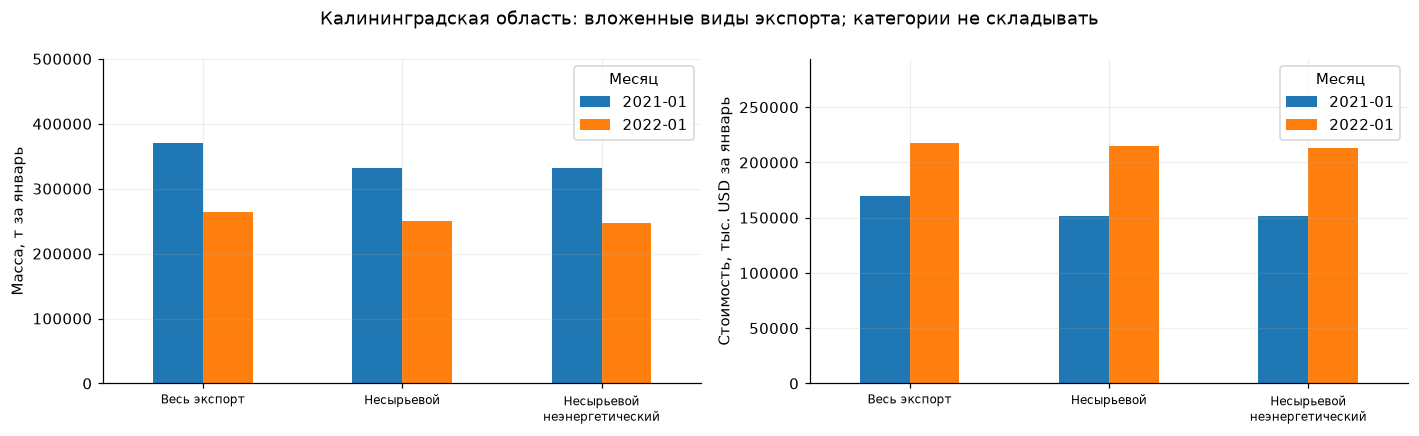

,export_scope,metric,base_period,current_period,base_value,current_value,change_pct
0,all_exports,weight_tonnes,2021-01,2022-01,370593,264589,-28.60
1,non_raw_exports,weight_tonnes,2021-01,2022-01,331587,249485,-24.76
2,non_raw_non_energy_exports,weight_tonnes,2021-01,2022-01,331086,247203,-25.34
3,all_exports,trade_value_thousand_usd,2021-01,2022-01,169334,217751,28.59
4,non_raw_exports,trade_value_thousand_usd,2021-01,2022-01,151763,215015,41.68
5,non_raw_non_energy_exports,trade_value_thousand_usd,2021-01,2022-01,151532,213455,40.86
6,all_exports,enterprise_count,2021-01,2022-01,183,198,8.20
7,non_raw_exports,enterprise_count,2021-01,2022-01,169,188,11.24
8,non_raw_non_energy_exports,enterprise_count,2021-01,2022-01,165,185,12.12


In [13]:
export_comparison = pd.DataFrame()
if "exports_clean.csv" in tables:
    region_totals = kaliningrad.loc[kaliningrad["enterprise_group"].eq("Всего")].copy()
    scope_labels = {"all_exports": "Весь экспорт", "non_raw_exports": "Несырьевой", "non_raw_non_energy_exports": "Несырьевой неэнергетический"}
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for metric, ax, label in [("weight_tonnes", axes[0], "Масса, т за январь"),
                               ("trade_value_thousand_usd", axes[1], "Стоимость, тыс. USD за январь")]:
        pivot = region_totals.pivot(index="export_scope", columns="period", values=metric).reindex(scope_labels)
        pivot.index = pivot.index.map(scope_labels).str.replace("Несырьевой неэнергетический", "Несырьевой\nнеэнергетический", regex=False)
        pivot.plot.bar(ax=ax, rot=0)
        ax.set(xlabel="", ylabel=label)
        ax.tick_params(axis="x", labelsize=8)
        ax.legend(title="Месяц")
        ax.set_ylim(0, float(pivot.max().max()) * 1.35)
    fig.suptitle("Калининградская область: вложенные виды экспорта; категории не складывать")
    fig.tight_layout()
    figures["kaliningrad_exports"] = fig
    plt.show()

    # Изменение рассчитывается отдельно по каждой метрике и виду экспорта.
    comparison_rows = []
    for metric in ("weight_tonnes", "trade_value_thousand_usd", "enterprise_count"):
        values = region_totals.pivot(index="export_scope", columns="period", values=metric)
        periods = sorted(values.columns)
        if len(periods) == 2:
            base, current = periods
            change = (values[current] / values[base].where(values[base].ne(0)) - 1) * 100
            for scope in values.index:
                comparison_rows.append({"export_scope": scope, "metric": metric,
                                        "base_period": base, "current_period": current,
                                        "base_value": values.at[scope, base], "current_value": values.at[scope, current],
                                        "change_pct": change.loc[scope]})
    export_comparison = pd.DataFrame(comparison_rows)
    display(export_comparison.round(2))
else:
    print('Экспортные оригиналы не включены в эту сборку.')


### Проверка опубликованных индексов

«Темп роста 71,4%» означает 0,714 от базы, то есть снижение примерно на 28,6%.
Индекс и процент изменения — разные величины.
Расхождения сравниваются с видимыми округлёнными числами; они не доказывают ошибку первоисточника.
Порог 0,15 процентного пункта — диагностическое правило, не статистический критерий качества.

**Файл диагностики:** `data/processed/export_growth_checks.csv`.
Базовые значения, текущие значения и опубликованные индексы взяты из тех же трёх XLSX раздела 7;
отношение и разность вычислены обработчиком. `source_id` и `source_locator` позволяют найти исходную ячейку.



In [14]:
if "exports_clean.csv" in tables:
    growth = tables["export_growth_checks.csv"]
    growth_counts = growth.groupby(["export_scope", "check_status"]).size().unstack(fill_value=0)
    display(growth_counts)
    # fill_value=0 здесь означает отсутствие записей в категории диагностики; факты не заполняются нулями.
    display(growth.loc[growth["check_status"].eq("displayed_values_differ"),
                       ["export_scope", "reporting_geography", "enterprise_group", "metric", "base_value", "current_value",
                        "reported_growth_index_pct", "calculated_growth_index_pct", "difference_pp", "source_locator"]].head(12))
    print("При нулевой базе расчётный индекс оставлен пустым.")
else:
    print('Экспортные оригиналы не включены в эту сборку.')


check_status,displayed_values_differ,within_rounding_tolerance,zero_base
export_scope,,,
all_exports,61,1020,47
non_raw_exports,69,1005,54
non_raw_non_energy_exports,78,996,54


,export_scope,reporting_geography,enterprise_group,metric,base_value,current_value,reported_growth_index_pct,calculated_growth_index_pct,difference_pp,source_locator
118,all_exports,КОСТРОМСКАЯ ОБЛАСТЬ,Средние предприятия,weight_tonnes,133,242,182.6,181.9549,0.6451,Лист1!I56
143,all_exports,ЛИПЕЦКАЯ ОБЛАСТЬ,Средние предприятия,trade_value_thousand_usd,1245,18105,1454.5,1454.2169,0.2831,Лист1!J66
178,all_exports,ОРЛОВСКАЯ ОБЛАСТЬ,Средние предприятия,weight_tonnes,769,9159,1191.3,1191.0273,0.2727,Лист1!I81
214,all_exports,ТАМБОВСКАЯ ОБЛАСТЬ,Средние предприятия,weight_tonnes,126,7386,5859.1,5861.9048,-2.8048,Лист1!I96
215,all_exports,ТАМБОВСКАЯ ОБЛАСТЬ,Средние предприятия,trade_value_thousand_usd,20,1673,8370.5,8365,5.5,Лист1!J96
418,all_exports,АСТРАХАНСКАЯ ОБЛАСТЬ,Средние предприятия,weight_tonnes,20,58,283.4,290,-6.6,Лист1!I181
419,all_exports,АСТРАХАНСКАЯ ОБЛАСТЬ,Средние предприятия,trade_value_thousand_usd,106,117,109.9,110.3774,-0.4774,Лист1!J181
439,all_exports,РЕСПУБЛИКА КРЫМ,Малые предприятия,weight_tonnes,34,36,105.7,105.8824,-0.1824,Лист1!I190
440,all_exports,РЕСПУБЛИКА КРЫМ,Малые предприятия,trade_value_thousand_usd,24,212,869.5,883.3333,-13.8333,Лист1!J190
442,all_exports,РЕСПУБЛИКА КРЫМ,Средние предприятия,weight_tonnes,126,145,115.9,115.0794,0.8206,Лист1!I191


При нулевой базе расчётный индекс оставлен пустым.


## 8. Транзитный XLS: что именно можно исследовать

Строка — **товарная позиция декларации**, не уникальная физическая отправка.
Файл содержит товары с кодом 2204 (вино), оформление конца 2016 года и завершение до января 2017.
Страны и таможни не доказывают соответствие Калининградскому коридору.

В очищенном CSV нет реквизитов участников и транспорта; хеш связывает товары одной декларации.
Смотрим количество записей, пропуски, даты и состав выборки.
`rail` не означает подтверждённое сухопутное пересечение коридора, `water` сохраняет неоднозначность «морской/речной».

**Откуда взяты данные:** файл `2204_tranzit_EN.xls`, присланный вами в чат.
Организация-составитель, сайт публикации и методика отбора пока не установлены.

- Неизменённый оригинал: `data/raw/customs_transit_2204/b1ca7b748adde5e3ec68a978cb9b1237ab5a45c8bbd75e509daff181bc0d3fa6.xls`; лист `Транзит`.
- Очищенные товарные строки: `data/processed/transit_items_clean.csv`.
- Производная месячная сводка: `data/processed/transit_monthly_summary.csv`.
- Паспорт: `source_id = customs_transit_2204__b1ca7b748add`; `source_locator` указывает строку оригинала.

Ноутбук читает очищенный CSV. Исходные реквизиты участников и транспорта остаются в оригинале и не выводятся в обзор.



In [15]:
transit_profile = pd.DataFrame()
if "transit_items_clean.csv" in tables:
    transit = tables["transit_items_clean.csv"].copy()
    for column in ("item_gross_kg", "item_gross_tonnes", "item_net_kg", "item_net_tonnes", "item_invoice_usd", "transit_days"):
        transit[column] = numeric_column(transit, column)
    for column in ("registered_date", "completed_date"):
        transit[column] = pd.to_datetime(transit[column].replace("", pd.NA), format="%Y-%m-%d", errors="raise")
    transit_profile = pd.DataFrame([
        {"metric": "Товарных строк", "value": len(transit)},
        {"metric": "Уникальных деклараций в выборке", "value": transit["declaration_id_hash"].nunique()},
        {"metric": "Начало регистрации", "value": str(transit["registered_date"].min().date())},
        {"metric": "Конец регистрации", "value": str(transit["registered_date"].max().date())},
        {"metric": "Последнее завершение", "value": str(transit["completed_date"].max().date())},
        {"metric": "Нетто отсутствует, строк", "value": int(transit["item_net_tonnes"].isna().sum())},
        {"metric": "Нетто отсутствует, %", "value": round(transit["item_net_tonnes"].isna().mean() * 100, 2)},
    ])
    display(transit_profile)
    display(transit["commodity_code"].str[:4].value_counts().rename_axis("commodity_prefix").rename("item_rows").reset_index())
    display(transit[["registered_date", "completed_date", "origin_country_code", "destination_country_code", "actual_mode",
                     "commodity_code", "item_gross_tonnes", "item_net_tonnes", "quality_flags"]].head(8))
else:
    print('Транзитный оригинал не включён в эту сборку.')


,metric,value
0,Товарных строк,8253
1,Уникальных деклараций в выборке,3485
2,Начало регистрации,2016-11-30
3,Конец регистрации,2016-12-31
4,Последнее завершение,2017-01-11
5,"Нетто отсутствует, строк",8004
6,"Нетто отсутствует, %",96.98


,commodity_prefix,item_rows
0,2204,8253


,registered_date,completed_date,origin_country_code,destination_country_code,actual_mode,commodity_code,item_gross_tonnes,item_net_tonnes,quality_flags
0,2016-12-01,2016-12-02,LT,RU,road,2204109601,22.045,<NA>,net_weight_missing
1,2016-12-01,2016-12-02,LT,RU,road,2204109801,22.045,<NA>,net_weight_missing
2,2016-12-01,2016-12-02,LT,RU,road,2204109801,22.045,<NA>,net_weight_missing
3,2016-12-01,2016-12-02,LT,RU,road,2204218000,11.94,<NA>,net_weight_missing
4,2016-12-01,2016-12-02,LT,RU,road,2204217900,8.75,<NA>,net_weight_missing
5,2016-12-01,2016-12-06,LT,KZ,road,2204218300,13.728,<NA>,net_weight_missing
6,2016-12-01,2016-12-06,LT,KZ,road,2204218400,7.722,<NA>,net_weight_missing
7,2016-12-01,2016-12-14,DK,TJ,road,2204219800,0.066792,<NA>,net_weight_missing


,mode,item_rows,share_pct
0,road,8087,97.99
1,rail,149,1.81
2,water,15,0.18
3,air,2,0.02


,origin_country_code,destination_country_code,item_rows
0,LV,RU,3935
1,LT,RU,2128
2,RU,RU,288
3,GE,RU,208
4,LV,KZ,168
5,PL,RU,89
6,DK,RU,81
7,DE,RU,75
8,IT,RU,71
9,ZA,RU,68


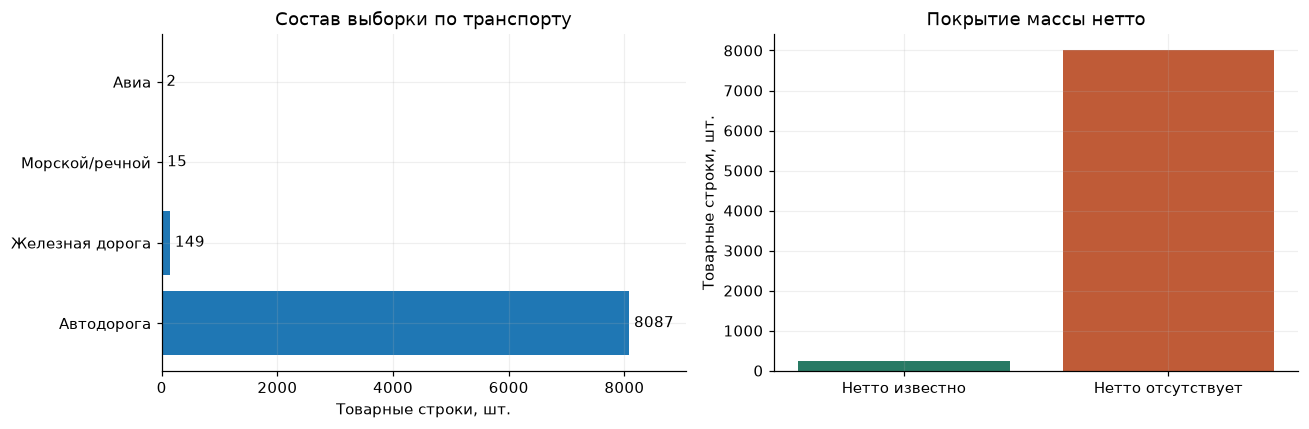

Это доли записей выборки, а не доли транспортного рынка или тоннажа коридора.


In [16]:
if "transit_items_clean.csv" in tables:
    mode_names = {"road": "Автодорога", "rail": "Железная дорога", "water": "Морской/речной", "air": "Авиа", "other": "Другой", "": "Не указан"}
    mode_counts = transit["actual_mode"].value_counts().rename_axis("mode").rename("item_rows").reset_index()
    mode_counts["share_pct"] = mode_counts["item_rows"] / len(transit) * 100
    display(mode_counts.round(2))
    country_pairs = transit.groupby(["origin_country_code", "destination_country_code"]).size().sort_values(ascending=False).rename("item_rows").reset_index()
    display(country_pairs.head(10))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    labels = mode_counts["mode"].map(mode_names)
    mode_bars = axes[0].barh(labels, mode_counts["item_rows"])
    axes[0].bar_label(mode_bars, padding=3, fmt="%d")
    axes[0].set_xlim(0, float(mode_counts["item_rows"].max()) * 1.12)
    axes[0].set(title="Состав выборки по транспорту", xlabel="Товарные строки, шт.")
    net_presence = transit["item_net_tonnes"].notna().value_counts().reindex([True, False], fill_value=0)
    axes[1].bar(["Нетто известно", "Нетто отсутствует"], net_presence.values, color=["#287a64", "#bf5b37"])
    axes[1].set(title="Покрытие массы нетто", ylabel="Товарные строки, шт.")
    fig.tight_layout()
    figures["transit_composition"] = fig
    plt.show()
    print("Это доли записей выборки, а не доли транспортного рынка или тоннажа коридора.")
else:
    print('Транзитный оригинал не включён в эту сборку.')


### Срок между оформлением и завершением

Чтобы декларация с несколькими товарами не получала больший вес, сначала проверяем одинаковость дат
внутри декларации и оставляем одну запись на декларацию. Это календарный интервал между двумя полями;
он не равен чистому времени движения, простою или эффекту транспортного решения.

**Исходные поля:** `registered_date` и `completed_date` из `data/processed/transit_items_clean.csv`.
Они получены из полей «Дата оформления декларации» и «Дата завершения транзита» листа `Транзит`
в `2204_tranzit_EN.xls`. Календарный интервал рассчитывается в этой ячейке; отдельного источника длительности нет.



Деклараций с двумя датами: 3464 из 3485


,calendar_days
count,3464.000000
mean,2.366051
std,2.374414
min,0.000000
50%,2.000000
90%,4.000000
95%,7.000000
max,25.000000


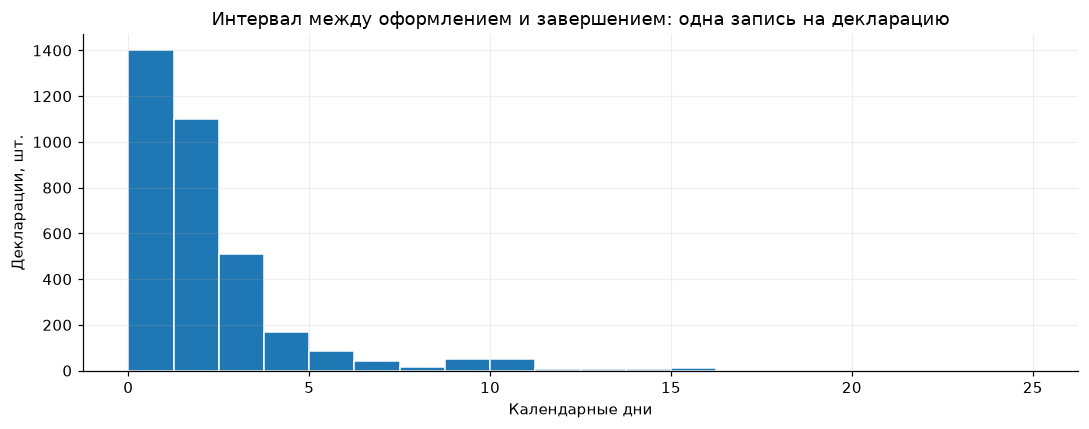

In [17]:
if "transit_items_clean.csv" in tables:
    date_columns = ["registered_date", "completed_date"]
    date_consistency = transit.groupby("declaration_id_hash")[date_columns].nunique(dropna=False)
    if date_consistency.gt(1).any(axis=None):
        raise ValueError("Внутри одной декларации разные даты; распределение требует отдельного разбора.")
    declaration_dates = transit.drop_duplicates("declaration_id_hash").copy()
    declaration_dates["calendar_days"] = (declaration_dates["completed_date"] - declaration_dates["registered_date"]).dt.days
    known_days = declaration_dates["calendar_days"].dropna()
    print("Деклараций с двумя датами:", len(known_days), "из", len(declaration_dates))
    display(known_days.describe(percentiles=[0.5, 0.9, 0.95]).to_frame("calendar_days"))
    fig, ax = plt.subplots()
    ax.hist(known_days.astype(float), bins=20, edgecolor="white")
    ax.set(title="Интервал между оформлением и завершением: одна запись на декларацию",
           xlabel="Календарные дни", ylabel="Декларации, шт.")
    fig.tight_layout()
    figures["transit_calendar_days"] = fig
    plt.show()
else:
    print('Транзитный оригинал не включён в эту сборку.')


### Сводка товарных масс

Суммируются веса **товарных позиций**, а не повторяющийся общий вес декларации.
Даже разные декларации могут отражать этапы движения одного груза, поэтому результат не является уникальным тоннажем.
Отсутствующие веса нетто не заменены брутто. В месячной таблице стоит **месяц оформления**, а не завершения.
Количество деклараций между группами складывать нельзя.

**Подробные записи:** `data/processed/transit_items_clean.csv`.
**Сводка для сверки:** `data/processed/transit_monthly_summary.csv`.
Оба файла происходят из одного `2204_tranzit_EN.xls`; сводка не добавляет независимых наблюдений.



In [18]:
mass_checks = pd.DataFrame()
if "transit_items_clean.csv" in tables:
    monthly_summary = tables["transit_monthly_summary.csv"]
    display(monthly_summary.head(12))
    # Дополнительная точная сверка масштаба без округления float.
    raw_items = tables["transit_items_clean.csv"]
    def decimal_sum(values):
        known = [Decimal(v) for v in values if v != ""]
        return sum(known, Decimal(0)) if known else None

    mass_checks = []
    for kind in ("gross", "net"):
        item_sum = decimal_sum(raw_items[f"item_{kind}_tonnes"])
        grouped_sum = decimal_sum(monthly_summary[f"item_{kind}_sum_tonnes"])
        assert item_sum == grouped_sum, f"Сводка не совпадает по {kind}"
        mass_checks.append({"metric": kind, "known_item_rows": int(raw_items[f"item_{kind}_tonnes"].ne("").sum()),
                            "sum_item_tonnes": str(item_sum) if item_sum is not None else "нет значений",
                            "summary_matches": item_sum == grouped_sum})
    mass_checks = pd.DataFrame(mass_checks)
    display(mass_checks)
else:
    print('Транзитный оригинал не включён в эту сборку.')


,period,origin_country_code,destination_country_code,actual_mode,commodity_prefix,item_rows,...,known_gross_rows,item_gross_sum_tonnes,known_net_rows,item_net_sum_tonnes,source_id,quality_note
0,2016-11,GE,LV,road,2204,1,...,1,20.898,1,19.278,customs_transit_2204__b1ca7b748add,"Сумма товарных записей выборки, не уникальные отправки и не тоннаж коридора. Числ..."
1,2016-11,LV,RU,road,2204,1,...,1,20.9024,0,,customs_transit_2204__b1ca7b748add,"Сумма товарных записей выборки, не уникальные отправки и не тоннаж коридора. Числ..."
2,2016-11,ZA,RU,road,2204,9,...,9,215.4,0,,customs_transit_2204__b1ca7b748add,"Сумма товарных записей выборки, не уникальные отправки и не тоннаж коридора. Числ..."
3,2016-12,AB,RU,road,2204,65,...,65,1233.01315,36,653.1444,customs_transit_2204__b1ca7b748add,"Сумма товарных записей выборки, не уникальные отправки и не тоннаж коридора. Числ..."
4,2016-12,AB,UA,road,2204,2,...,2,9.6708,2,9.14064,customs_transit_2204__b1ca7b748add,"Сумма товарных записей выборки, не уникальные отправки и не тоннаж коридора. Числ..."
5,2016-12,AM,BY,road,2204,28,...,28,180.1445,0,,customs_transit_2204__b1ca7b748add,"Сумма товарных записей выборки, не уникальные отправки и не тоннаж коридора. Числ..."
6,2016-12,AM,CZ,road,2204,2,...,2,4.559,2,0,customs_transit_2204__b1ca7b748add,"Сумма товарных записей выборки, не уникальные отправки и не тоннаж коридора. Числ..."
7,2016-12,AM,EE,road,2204,1,...,1,0.02,0,,customs_transit_2204__b1ca7b748add,"Сумма товарных записей выборки, не уникальные отправки и не тоннаж коридора. Числ..."
8,2016-12,AM,LT,road,2204,2,...,2,9.359,0,,customs_transit_2204__b1ca7b748add,"Сумма товарных записей выборки, не уникальные отправки и не тоннаж коридора. Числ..."
9,2016-12,AT,RU,road,2204,1,...,1,20.47392,0,,customs_transit_2204__b1ca7b748add,"Сумма товарных записей выборки, не уникальные отправки и не тоннаж коридора. Числ..."


,metric,known_item_rows,sum_item_tonnes,summary_matches
0,gross,8253,57693.875802,True
1,net,249,2332.30661,True


## 9. Региональная книга: история, единицы и версии

Источник — предоставленная книга `Калининград_объединённые_данные.xlsx`, длинный лист «Все_данные_parquet». Паспорта сохраняют хеш и путь оригинала; исходный Parquet отдельно не передан. [Описание составителя регионального набора](https://tochno.st/datasets/regions_collection).

`regional_indicators.csv` содержит все строки, `regional_freight.csv` — три грузовых показателя. Строки широкого листа и копия экспорта сверены и не прибавлены как новые наблюдения. Региональная масса не доказывает перевозку между областью и основной частью РФ. Специальные коды сохранены; разные издания и спорные значения не выбраны автоматически. Дата исторической доступности факторов пока не подтверждена.


Региональный профиль:


,conflicting_version_keys,repeated_version_keys,rows,special_codes,wide_checks,wide_mismatches
0,3,346,20537,"{'-77777777': 1083, '-99999999': 279}",2576,0


Сверка копии экспорта: {'matched_period_rows': 24, 'mismatched_period_rows': 0, 'unavailable_period_rows': 0}


,indicator_name,unit,rows,first_year,last_year
0,Грузооборот автомобильного транспорта организаций всех видов деятельности,tonne_km,24,2001,2024
1,Отправление грузов железнодорожным транспортом общего пользования,tonnes,22,2001,2022
2,Перевозки грузов автомобильным транспортом организаций всех видов деятельности,tonnes,24,2001,2024


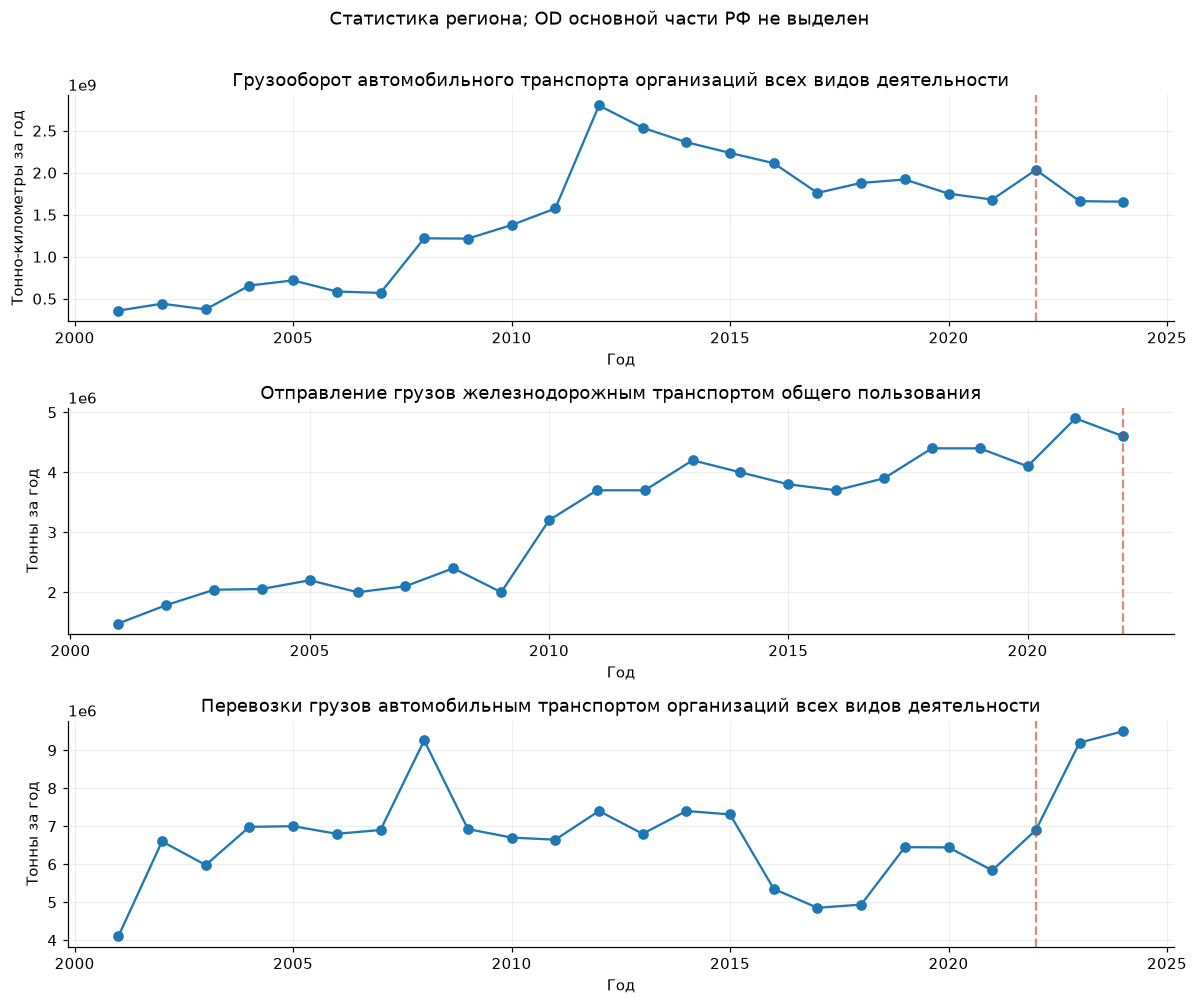

In [19]:
supplemental_quality = json.loads((ROOT / "data/processed/supplemental_quality.json").read_text(encoding="utf-8"))
print("Региональный профиль:")
display(pd.DataFrame([supplemental_quality.get("regional", {})]))
print("Сверка копии экспорта:", supplemental_quality.get("combined_export_checks", {}))
regional = tables.get("regional_freight.csv", pd.DataFrame()).copy()
if not regional.empty:
    regional["value"] = numeric_column(regional, "value")
    regional["year"] = pd.to_numeric(regional["period"], errors="raise")
    display(regional.groupby(["indicator_name", "unit"]).agg(rows=("period", "size"), first_year=("year", "min"), last_year=("year", "max")).reset_index())
    series = list(regional.groupby(["indicator_code", "indicator_name", "unit"]))
    fig, axes = plt.subplots(len(series), 1, figsize=(11, 3 * len(series)), squeeze=False)
    for ax, ((indicator, label, unit), group) in zip(axes.flat, series):
        group = group.sort_values("year")
        ax.plot(group["year"], group["value"], marker="o")
        ax.set(title=label, xlabel="Год", ylabel={"tonnes": "Тонны за год", "tonne_km": "Тонно-километры за год"}.get(unit, unit))
        ax.axvline(2022, color="#b44830", linestyle="--", alpha=0.6)
    fig.suptitle("Статистика региона; OD основной части РФ не выделен", y=1.01)
    fig.tight_layout()
    figures["regional_freight"] = fig
    plt.show()
else:
    print("Региональная книга не включена в эту сборку.")


## 10. Морские публикации и LTG: сопоставимость рядов

`supplemental_freight.csv` содержит предоставленные производные CSV. Для каждой строки доступны ссылка, указатель строки, охват, направление, точность и связи с включёнными HTML/PDF. Совпадение хеша подтверждает неизменность оригинала, но не является человеческой сверкой извлечённого числа.

На морском графике показаны отдельные опубликованные значения. «Более» означает нижнюю границу, «около» — приблизительную величину. Смена флота, включение другой линии и переход от вагонов к общему итогу меняют объект измерения. Груз на пароме относится к морю. В LTG весь транзит, международные перевозки и коридор разделены; оценка из доли имеет статус `estimated`. Расхождение 2024 года сохранено.


,series_id,direction_scope,measurement_scope,precision,status,unit,rows,first_period,last_period
0,ferry_cargo,inbound,Состав перечисленных групп неполный или расходится с итогом в ряде месяцев; не су...,as_published,observed,tonnes,60,2022-07,2023-07
1,ferry_cargo,outbound,Состав перечисленных групп неполный или расходится с итогом в ряде месяцев; не су...,as_published,observed,tonnes,6,2023-05,2023-07
2,ferry_forms,inbound,Июль: компоненты в сумме на 400 т выше заголовочного итога,as_published,observed,tonnes,2,2023-07,2023-07
3,ferry_forms,inbound,"Частичный охват: паромы оператора, не все морские суда",as_published,observed,tonnes,6,2023-04,2023-06
4,ferry_forms,outbound,Июль: компоненты в сумме на 400 т выше заголовочного итога,as_published,observed,tonnes,2,2023-07,2023-07
5,ferry_forms,outbound,"Частичный охват: паромы оператора, не все морские суда",as_published,observed,tonnes,4,2023-05,2023-06
6,ferry_monthly,both,оба направления; Усть-Луга — Балтийск и Санкт-Петербург — Пионерский,as_published,observed,tonnes,3,2025-03,2025-05
7,ferry_monthly,both,оба направления; Усть-Луга — Балтийск и Санкт-Петербург — Пионерский,lower_bound,observed,tonnes,2,2025-01,2025-02
8,ferry_monthly,both,оба направления; паромы Усть-Луга — Балтийск,approximate,observed,tonnes,4,2024-03,2024-11
9,ferry_monthly,both,оба направления; паромы Усть-Луга — Балтийск,as_published,observed,tonnes,9,2023-05,2025-08


,period,series_id,original_value,original_unit,direction_scope,transport_form,precision,formula,quality_note,source_url
0,2022-07,ferry_cargo,36420,тонны,inbound,,as_published,,Состав перечисленных групп неполный или расходится с итогом в ряде месяцев; не су...,https://obl.ru/pressa/news/obemy-perevozok-rastut/
1,2022-07,ferry_cargo,14715,тонны,inbound,,as_published,,Состав перечисленных групп неполный или расходится с итогом в ряде месяцев; не су...,https://obl.ru/pressa/news/obemy-perevozok-rastut/
2,2022-07,ferry_cargo,4270,тонны,inbound,,as_published,,Состав перечисленных групп неполный или расходится с итогом в ряде месяцев; не су...,https://obl.ru/pressa/news/obemy-perevozok-rastut/
3,2022-07,ferry_cargo,1400,тонны,inbound,,as_published,,Состав перечисленных групп неполный или расходится с итогом в ряде месяцев; не су...,https://obl.ru/pressa/news/obemy-perevozok-rastut/
4,2022-07,ferry_cargo,9490,тонны,inbound,накатная техника,as_published,,Состав перечисленных групп неполный или расходится с итогом в ряде месяцев; не су...,https://obl.ru/pressa/news/obemy-perevozok-rastut/
5,2022-08,ferry_cargo,28000,тонны,inbound,,as_published,,Состав перечисленных групп неполный или расходится с итогом в ряде месяцев; не су...,https://obl.ru/pressa/news/avgust-obyemy-perevozok-stabilny/
6,2022-08,ferry_cargo,15000,тонны,inbound,,as_published,,Состав перечисленных групп неполный или расходится с итогом в ряде месяцев; не су...,https://obl.ru/pressa/news/avgust-obyemy-perevozok-stabilny/
7,2022-08,ferry_cargo,403,тонны,inbound,,as_published,,Состав перечисленных групп неполный или расходится с итогом в ряде месяцев; не су...,https://obl.ru/pressa/news/avgust-obyemy-perevozok-stabilny/
8,2022-08,ferry_cargo,5000,тонны,inbound,,as_published,,Состав перечисленных групп неполный или расходится с итогом в ряде месяцев; не су...,https://obl.ru/pressa/news/avgust-obyemy-perevozok-stabilny/
9,2022-08,ferry_cargo,10300,тонны,inbound,накатная техника,as_published,,Состав перечисленных групп неполный или расходится с итогом в ряде месяцев; не су...,https://obl.ru/pressa/news/avgust-obyemy-perevozok-stabilny/


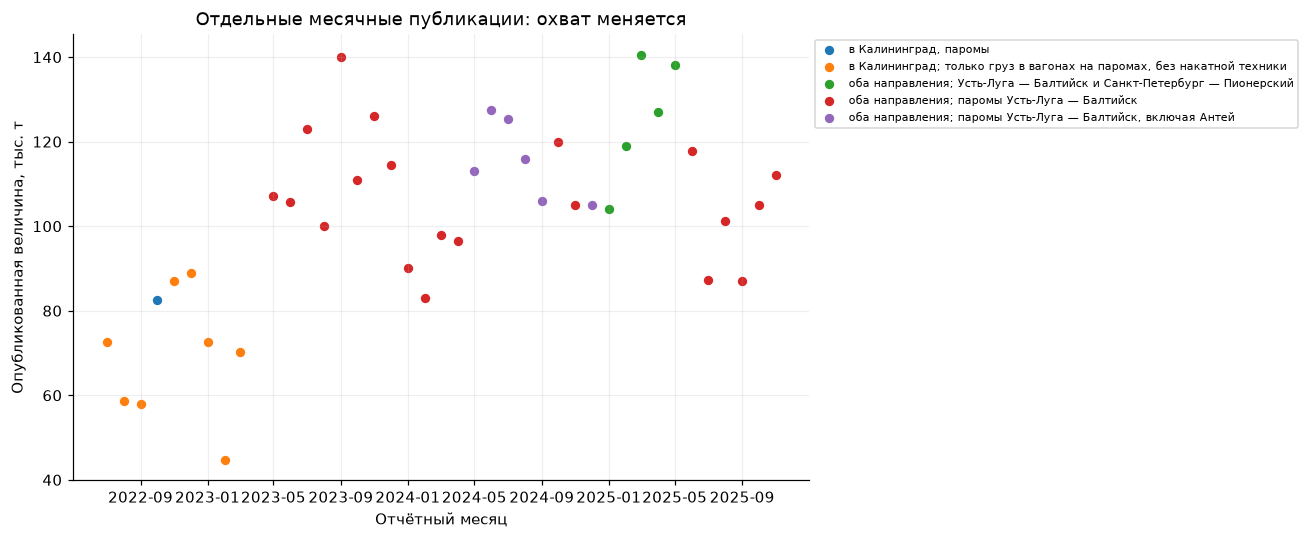

,period,series_id,measurement_scope,value,unit,status,formula,quality_flags
142,2021,ltg_international,Международные перевозки LTG,36400000,tonnes,observed,,provided_derivative
143,2021,ltg_all_transit,"Весь транзит LTG, включая другие OD",11500000,tonnes,observed,,provided_derivative
144,2022,ltg_international,Международные перевозки LTG,17100000,tonnes,observed,,provided_derivative
145,2022,ltg_all_transit,"Весь транзит LTG, включая другие OD",8100000,tonnes,observed,,provided_derivative
146,2023,ltg_international,Международные перевозки LTG,11800000,tonnes,observed,,provided_derivative
147,2023,ltg_all_transit,"Весь транзит LTG, включая другие OD",6500000,tonnes,observed,,provided_derivative
148,2023,ltg_kaliningrad_corridor,"Коридор через Литву, оба направления",6500000,tonnes,observed,,provided_derivative
149,2023,ltg_corridor_share,Доля коридора в международных перевозках,55,percent,observed,,provided_derivative
150,2024,ltg_international,Международные перевозки LTG,9600000,tonnes,observed,,provided_derivative
151,2024,ltg_all_transit,"Весь транзит LTG, включая другие OD",5300000,tonnes,observed,,provided_derivative


In [20]:
supplemental = tables.get("supplemental_freight.csv", pd.DataFrame()).copy()
new_series_profile = pd.DataFrame()
if not supplemental.empty:
    new_series_profile = supplemental.groupby(["series_id", "direction_scope", "measurement_scope", "precision", "status", "unit"], dropna=False).agg(rows=("period", "size"), first_period=("period", "min"), last_period=("period", "max")).reset_index()
    display(new_series_profile)
    display(supplemental[["period", "series_id", "original_value", "original_unit", "direction_scope", "transport_form", "precision", "formula", "quality_note", "source_url"]].head(12))
    monthly = supplemental.loc[supplemental["series_id"].eq("ferry_monthly")].copy()
    if not monthly.empty:
        monthly["date"] = pd.to_datetime(monthly["period"], format="%Y-%m")
        monthly["tonnes"] = numeric_column(monthly, "value")
        fig, ax = plt.subplots(figsize=(12, 5))
        for scope, group in monthly.groupby("measurement_scope"):
            ax.scatter(group["date"], group["tonnes"] / 1000, label=scope, s=26)
        ax.set(title="Отдельные месячные публикации: охват меняется", xlabel="Отчётный месяц", ylabel="Опубликованная величина, тыс. т")
        ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=7)
        fig.tight_layout()
        figures["operator_monthly_publications"] = fig
        plt.show()
    display(supplemental.loc[supplemental["mode"].eq("rail_land"), ["period", "series_id", "measurement_scope", "value", "unit", "status", "formula", "quality_flags"]])


## 11. Портовый каботаж и автомобильная граница

SeaNews: 26 исходных XLS/XLSX с накоплением с января. Основной и сравнительный годы, операторы и портовые итоги сохраняются отдельно. Месячная таблица — **оценки разностей** соседних сопоставимых накоплений; в ней отсутствуют строки с пропуском предшествующего месяца или отрицательной разностью. Нельзя складывать уровни и вложенные категории. Ни одна из таблиц не доказывает точный OD коридора.

`border_crossings.csv` измеряет пересечения грузовых автомобилей между областью и Польшей; это не тонны перевозок между областью и основной частью РФ.


,period,port,operator,cargo_group,value,unit,status,formula
0,2024-01,Порт Калининград,"""КМРП"" - Калининградский филиал ФГУП ""Нацрыбресурс""",Всего грузов,6500,tonnes,estimated,6500
1,2024-02,Порт Калининград,"""КМРП"" - Калининградский филиал ФГУП ""Нацрыбресурс""",Всего грузов,8400,tonnes,estimated,14900 - 6500
2,2024-03,Порт Калининград,"""КМРП"" - Калининградский филиал ФГУП ""Нацрыбресурс""",Всего грузов,11300,tonnes,estimated,26200 - 14900
3,2024-04,Порт Калининград,"""КМРП"" - Калининградский филиал ФГУП ""Нацрыбресурс""",Всего грузов,14600,tonnes,estimated,40800 - 26200
4,2024-05,Порт Калининград,"""КМРП"" - Калининградский филиал ФГУП ""Нацрыбресурс""",Всего грузов,12200,tonnes,estimated,53000 - 40800
5,2024-06,Порт Калининград,"""КМРП"" - Калининградский филиал ФГУП ""Нацрыбресурс""",Всего грузов,6800,tonnes,estimated,59800 - 53000
6,2024-07,Порт Калининград,"""КМРП"" - Калининградский филиал ФГУП ""Нацрыбресурс""",Всего грузов,16700,tonnes,estimated,76500 - 59800
7,2024-08,Порт Калининград,"""КМРП"" - Калининградский филиал ФГУП ""Нацрыбресурс""",Всего грузов,14100,tonnes,estimated,90600 - 76500
8,2024-09,Порт Калининград,"""КМРП"" - Калининградский филиал ФГУП ""Нацрыбресурс""",Всего грузов,7200,tonnes,estimated,97800 - 90600
9,2024-10,Порт Калининград,"""КМРП"" - Калининградский филиал ФГУП ""Нацрыбресурс""",Всего грузов,13000,tonnes,estimated,110800 - 97800


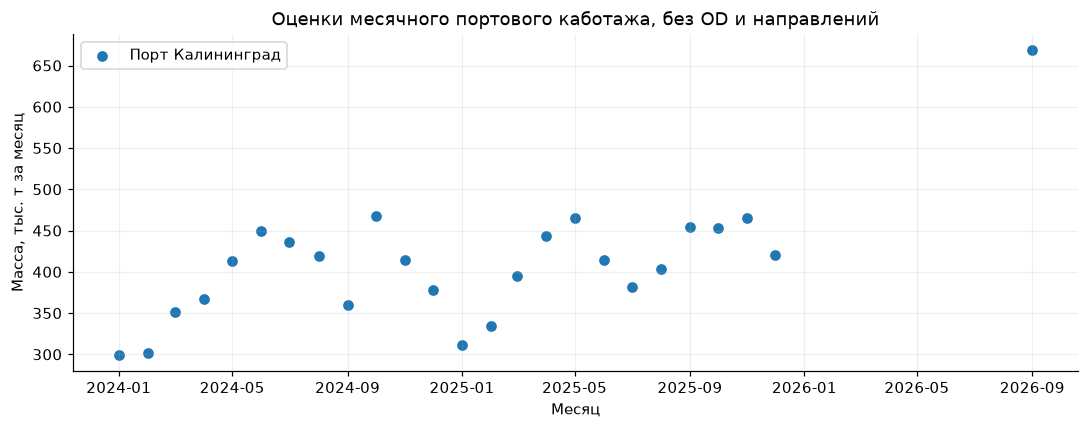

,crossing,direction_label,unit,rows,first_period,last_period
0,Багратионовск — Безледы,из Калининградской области в Польшу,пересечения грузовых автомобилей,57,2022-01,2026-09
1,Багратионовск — Безледы,из Польши в Калининградскую область,пересечения грузовых автомобилей,57,2022-01,2026-09
2,Мамоново-II — Гжехотки,из Калининградской области в Польшу,пересечения грузовых автомобилей,57,2022-01,2026-09
3,Мамоново-II — Гжехотки,из Польши в Калининградскую область,пересечения грузовых автомобилей,57,2022-01,2026-09


In [21]:
port_monthly = tables.get("port_cabotage_monthly.csv", pd.DataFrame()).copy()
if not port_monthly.empty:
    display(port_monthly[["period", "port", "operator", "cargo_group", "value", "unit", "status", "formula"]].head(12))
    port_totals = port_monthly.loc[port_monthly["measurement_scope"].eq("port_total") & port_monthly["cargo_group"].eq("Всего грузов")].copy()
    if not port_totals.empty:
        port_totals["date"] = pd.to_datetime(port_totals["period"], format="%Y-%m")
        port_totals["tonnes"] = numeric_column(port_totals, "value")
        fig, ax = plt.subplots()
        for port, group in port_totals.groupby("port"):
            ax.scatter(group["date"], group["tonnes"] / 1000, label=port)
        ax.set(title="Оценки месячного портового каботажа, без OD и направлений", xlabel="Месяц", ylabel="Масса, тыс. т за месяц")
        ax.legend()
        fig.tight_layout()
        figures["port_cabotage_monthly_estimates"] = fig
        plt.show()
borders = tables.get("border_crossings.csv", pd.DataFrame())
if not borders.empty:
    display(borders.groupby(["crossing", "direction_label", "unit"]).agg(rows=("period", "size"), first_period=("period", "min"), last_period=("period", "max")).reset_index())


## 12. Покрытие всех грузовых видов и новые замечания

Это карта пригодности данных, а не заполненная матрица тоннажа. Отсутствие авиационного ряда остаётся явным пробелом. Пассажирские расписания не включаются в грузовую задачу.

Порядок вашей следующей работы и шаблон запроса владельцам данных: [задачи Data Engineer](../docs/data-engineer-next-steps.md). Модель и точность ещё не заявлены. `review_status: pending` означает необходимость реальной человеческой сверки.


In [22]:
display(tables.get("freight_coverage.csv", pd.DataFrame()))
new_issues = tables.get("supplemental_issues.csv", pd.DataFrame())
if not new_issues.empty:
    display(new_issues.groupby(["dataset", "issue"]).size().rename("rows").reset_index())
    display(new_issues.loc[new_issues["issue"].isin(["conflicting_versions", "negative_difference", "scope_conflict", "component_total_mismatch"])].head(16))
print("Предметная проверка человеком:", supplemental_quality.get("human_review_completed", False))


,mode,datasets,directional_rows,both_directions_rows,coverage_status,limitation
0,sea,supplemental_freight.csv;port_cabotage_cumulative.csv;port_cabotage_monthly.csv,107,35,partial,"Часть операторов/линий; меняются направления, формы и охват. Каботаж порта без OD."
1,rail_land,regional_freight.csv;supplemental_freight.csv,2,18,partial,"Региональное отправление не равно OD; LTG — короткие годовые итоги, оба направлен..."
2,road,regional_freight.csv;border_crossings.csv,0,0,partial,Региональная масса и пересечения границы; нет подтверждённой массы OD.
3,air,,0,0,unavailable,В присланных файлах подтверждённого ряда грузовой массы OD нет.


,dataset,issue,rows
0,ferry_cargo,transport_form_in_cargo_list,9
1,ferry_monthly,component_total_mismatch,1
2,port_cabotage_monthly,missing_previous_month,520
3,port_cabotage_monthly,missing_value,4372
4,port_cabotage_monthly,negative_difference,8
5,rail_discrepancy,scope_conflict,2
6,regional_indicators,conflicting_versions,6
7,regional_indicators,multiple_versions,686


,dataset,source_id,source_locator,issue,related_locator,details
9,ferry_monthly,archive_ferry_monthly__e03556211e4a,CSV:row=13,component_total_mismatch,,как опубликовано; сумма компонентов больше на 400 т
10,rail_discrepancy,archive_rail_discrepancy__b1282b9b2eda,CSV:row=2,scope_conflict,,Не объединять с годовым рядом до разъяснения охвата
11,rail_discrepancy,archive_rail_discrepancy__b1282b9b2eda,CSV:row=3,scope_conflict,,Официальный округленный годовой итог; направления не указаны
250,regional_indicators,regional_combined__7e68c1f0d569,Все_данные_parquet!A7834:K7834,conflicting_versions,Все_данные_parquet!A7834:K7834,Сохранены все издания; автоматический выбор версии не выполнялся.
251,regional_indicators,regional_combined__7e68c1f0d569,Все_данные_parquet!A9652:K9652,conflicting_versions,Все_данные_parquet!A7834:K7834,Сохранены все издания; автоматический выбор версии не выполнялся.
262,regional_indicators,regional_combined__7e68c1f0d569,Все_данные_parquet!A7840:K7840,conflicting_versions,Все_данные_parquet!A7840:K7840,Сохранены все издания; автоматический выбор версии не выполнялся.
263,regional_indicators,regional_combined__7e68c1f0d569,Все_данные_parquet!A9658:K9658,conflicting_versions,Все_данные_parquet!A7840:K7840,Сохранены все издания; автоматический выбор версии не выполнялся.
684,regional_indicators,regional_combined__7e68c1f0d569,Все_данные_parquet!A8780:K8780,conflicting_versions,Все_данные_parquet!A8780:K8780,Сохранены все издания; автоматический выбор версии не выполнялся.
685,regional_indicators,regional_combined__7e68c1f0d569,Все_данные_parquet!A9468:K9468,conflicting_versions,Все_данные_parquet!A8780:K8780,Сохранены все издания; автоматический выбор версии не выполнялся.
1273,port_cabotage_monthly,seanews_2025_10__8845457c8cf3,Перекрестный!H255,negative_difference,Перекрестный!H252,Разность накоплений отрицательна; требуется сверка охвата/версий.


Предметная проверка человеком: False


## 13. Что передать команде

Таблица ниже — оценка пригодности имеющихся материалов, не утверждение цели и не выбор гипотез.
Для факторов нужны дата публикации/доступности и лаг, для сценарных параметров — объект и период действия.

**На чём основана оценка:** таблицы разделов 5–8 и их паспорта в `data/source_registry.json`.
Подробные пояснения: `docs/data-audit.md` и `docs/tables-quality.md`.
Рекомендации в этой таблице составлены при анализе данных с помощью ИИ; это не значения из внешней публикации.



In [23]:
suitability = pd.DataFrame([
    {"dataset": "regional_indicators.csv / regional_freight.csv", "use": "Региональный контекст и кандидаты факторов", "limitation": "OD коридора не выделен; версии и специальные коды требуют проверки", "next_step": "Получить паспорт Parquet и даты исторической доступности"},
    {"dataset": "supplemental_freight.csv", "use": "Частичные морские и железнодорожные показатели", "limitation": "Меняются охват и точность; общий транзит и коридор различаются", "next_step": "Сверить производные CSV с первичными HTML/PDF и согласовать целевое покрытие"},
    {"dataset": "port_cabotage_cumulative.csv / port_cabotage_monthly.csv", "use": "Проверка масштаба портового каботажа", "limitation": "Нет OD и направлений; месяцы — оценки разностей, не наблюдения", "next_step": "Разобрать отрицательные разности и изменения состава операторов"},
    {"dataset": "border_crossings.csv / freight_coverage.csv", "use": "Счётчики границы и карта пробелов", "limitation": "Автомобили не равны тоннам; авиационный OD отсутствует", "next_step": "Запросить массу по нужному OD у владельцев перевозочных данных"},
    {"dataset": "candidate_observations.csv", "use": "Кандидат узкой годовой цели", "limitation": "При наличии первоисточника: только линия, 9 точек на направление; в частичном комплекте может быть пуст", "next_step": "ML Lead и Team Lead выбирают цель и временную проверку"},
    {"dataset": "context_observations.csv", "use": "Проверка масштаба и охвата", "limitation": "Иные объекты, без направления; не продолжение целевого ряда", "next_step": "Сверить определения с первоисточником"},
    {"dataset": "exports_clean.csv / exports_kaliningrad.csv", "use": "Описание внешней торговли; кандидат контекста", "limitation": "Два января, вложенные категории; нет подтверждённого OD и транспорта", "next_step": "Найти методику, публикацию, более длинную историю и дату доступности"},
    {"dataset": "transit_items_clean.csv / transit_monthly_summary.csv", "use": "Описание товарной выборки и качества полей", "limitation": "Группа 2204, конец 2016; нетто часто пусто; коридор и уникальность отправок не доказаны", "next_step": "Установить происхождение и критерии отбора; запросить нужный период и географию"},
    {"dataset": "scenario_parameters.csv", "use": "Справочные заявленные мощности объектов", "limitation": "Разные единицы, нет дат и доступности; не мощность всей цепочки", "next_step": "Аналитик подтверждает параметры выбранных действий"},
    {"dataset": "factors.csv", "use": "Пока только схема", "limitation": "Нет строк и подтверждённых доступных факторов", "next_step": "Заполнять после выбора цели и правил исторической доступности"},
    {"dataset": "Каталог, PDF, страницы, DOCX", "use": "Поиск источников и предметный контекст", "limitation": "Сохранённый материал не равен извлечённому ряду; расписание — план", "next_step": "Проверять первоисточники и извлекать совместимые показатели"},
])
display(suitability)
print("Готово к передаче: инвентаризация, источники, пропуски, проверки ключей, графики и ограничения.")


,dataset,use,limitation,next_step
0,regional_indicators.csv / regional_freight.csv,Региональный контекст и кандидаты факторов,OD коридора не выделен; версии и специальные коды требуют проверки,Получить паспорт Parquet и даты исторической доступности
1,supplemental_freight.csv,Частичные морские и железнодорожные показатели,Меняются охват и точность; общий транзит и коридор различаются,Сверить производные CSV с первичными HTML/PDF и согласовать целевое покрытие
2,port_cabotage_cumulative.csv / port_cabotage_monthly.csv,Проверка масштаба портового каботажа,"Нет OD и направлений; месяцы — оценки разностей, не наблюдения",Разобрать отрицательные разности и изменения состава операторов
3,border_crossings.csv / freight_coverage.csv,Счётчики границы и карта пробелов,Автомобили не равны тоннам; авиационный OD отсутствует,Запросить массу по нужному OD у владельцев перевозочных данных
4,candidate_observations.csv,Кандидат узкой годовой цели,"При наличии первоисточника: только линия, 9 точек на направление; в частичном ком...",ML Lead и Team Lead выбирают цель и временную проверку
5,context_observations.csv,Проверка масштаба и охвата,"Иные объекты, без направления; не продолжение целевого ряда",Сверить определения с первоисточником
6,exports_clean.csv / exports_kaliningrad.csv,Описание внешней торговли; кандидат контекста,"Два января, вложенные категории; нет подтверждённого OD и транспорта","Найти методику, публикацию, более длинную историю и дату доступности"
7,transit_items_clean.csv / transit_monthly_summary.csv,Описание товарной выборки и качества полей,"Группа 2204, конец 2016; нетто часто пусто; коридор и уникальность отправок не до...",Установить происхождение и критерии отбора; запросить нужный период и географию
8,scenario_parameters.csv,Справочные заявленные мощности объектов,"Разные единицы, нет дат и доступности; не мощность всей цепочки",Аналитик подтверждает параметры выбранных действий
9,factors.csv,Пока только схема,Нет строк и подтверждённых доступных факторов,Заполнять после выбора цели и правил исторической доступности


Готово к передаче: инвентаризация, источники, пропуски, проверки ключей, графики и ограничения.


### Ваши заметки после просмотра

Дополните блок своими выводами. Человеческая приёмка отмечается только после реальной сверки с оригиналом.
ИИ подготовил этот ноутбук и автоматические проверки; это не подпись человека под методикой источника.


In [24]:
review_notes = {
    "reviewer": "",                 # Кто просмотрел и сверил исходные ячейки.
    "review_date": "",              # Дата фактической проверки.
    "checked_sources_and_cells": "", # Какие файлы, листы, строки и единицы проверены.
    "findings": "",                 # Что вы увидели в таблицах и на графиках.
    "questions_for_team": "",       # Например: какой ряд выбрать для первой версии?
    "human_review_completed": False,
}
display(pd.DataFrame([review_notes]))


,reviewer,review_date,checked_sources_and_cells,findings,questions_for_team,human_review_completed
0,,,,,,False


## 14. Сохранить обзор для передачи (по желанию)

По умолчанию эта ячейка ничего не записывает. Установите `SAVE_REVIEW = True`, чтобы сохранить
таблицы обзора, графики PNG и текстовый отчёт в `reports/generated/dataset_overview/<версия>/`.
Повторный запуск обновит только файлы этого обзора; исходники и подготовленные CSV не меняются.
Выводы ноутбука с реальными данными остаются в игнорируемой Git папке.


In [25]:
SAVE_REVIEW = False
if SAVE_REVIEW:
    output_dir = ROOT / "reports/generated/dataset_overview" / manifest["data_version"]
    output_dir.mkdir(parents=True, exist_ok=True)
    review_tables = {"inventory": inventory, "missing_profile": missing_profile, "key_checks": key_checks,
                     "export_comparison": export_comparison, "transit_profile": transit_profile,
                     "suitability": suitability, "mass_checks": mass_checks,
                     "freight_coverage": tables.get("freight_coverage.csv", pd.DataFrame()),
                     "new_series_profile": new_series_profile}
    for name, frame in review_tables.items():
        frame.to_csv(output_dir / f"{name}.csv", index=False, encoding="utf-8-sig")
    for name, fig in figures.items():
        fig.savefig(output_dir / f"{name}.png", dpi=160, bbox_inches="tight")
    (output_dir / "review_notes.json").write_text(json.dumps(review_notes, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    report_lines = ["# Обзор датасетов", "", f"Версия данных: {manifest['data_version']}", "",
                    "Проверка комплекта: пройдена. Цель прогноза ожидает решения команды.", "",
                    "## Пригодность материалов", ""]
    for row in suitability.to_dict("records"):
        report_lines.extend([f"### {row['dataset']}", row["use"], row["limitation"], row["next_step"], ""])
    report_lines.extend(["## Человеческая проверка", json.dumps(review_notes, ensure_ascii=False, indent=2), "",
                         "ИИ подготовил ноутбук; статус проверки человеком задаётся после фактической сверки.", ""])
    (output_dir / "overview.md").write_text("\n".join(report_lines), encoding="utf-8")
    print("Обзор сохранён:", output_dir)
else:
    print("Сохранение выключено. Для экспорта таблиц, отчёта и графиков задайте SAVE_REVIEW = True.")


Сохранение выключено. Для экспорта таблиц, отчёта и графиков задайте SAVE_REVIEW = True.


### Документы рядом

- `README.md` — ссылки на оригиналы и подготовленные файлы.
- `docs/contracts.md` — поля и единицы таблиц.
- `docs/tables-quality.md` — проверка четырёх пользовательских файлов.
- `docs/data-audit.md` — покрытие и варианты целевого ряда.
- `docs/data-preparation.md` — повторная сборка и передача оригиналов.

Для сохранения всего выполненного ноутбука и HTML без помещения реальных выводов в Git
используйте команды из `notebooks/README.md`.
